# Partie 4 — Théorie des valeurs extrêmes (EVT)

**Problème :** pour les niveaux très élevés (99,9 %, 99,99 %), l'historique manque de données
(5 jours au-delà de la VaR 99,9 %, aucun au-delà de 99,99 %) et la loi normale sous-estime la queue.

**Idée de l'EVT :** ne modéliser que les **k pires pertes**. Au-delà d'un seuil, elles suivent une loi de Pareto,
caractérisée par un seul paramètre, l'**indice de queue ξ** (ξ = 0 : queue fine ; ξ > 0 : queue épaisse).
On estime ξ, puis on **extrapole** la queue au-delà des données observées.

In [6]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from src.data import load_prices, compute_returns, portfolio_losses
from src.risk_measures import var_hist, es_hist, var_gaussien, es_gaussien, var_kde, es_kde
from src.evt import hill, pickands, var_evt, es_evt

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
returns = compute_returns(prices)
losses = portfolio_losses(returns)
pertes_triees = losses.sort_values(ascending=False)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Les pires pertes et les limites de la loi normale

In [7]:
print(pertes_triees.head(10))

var_g = var_gaussien(losses, 0.999)
print("\nVaR gaussienne 99,9 % :", round(var_g * 100, 2), "%")
print("Dépassements attendus :", round(0.001 * len(losses), 1))
print("Dépassements observés :", (losses > var_g).sum())

Date
2020-03-12    0.131022
2020-03-18    0.120566
2020-03-09    0.107869
2016-06-24    0.086478
2008-10-06    0.086413
2008-01-21    0.073587
2008-10-08    0.068184
2008-10-10    0.067433
2020-06-11    0.064798
2021-11-26    0.064509
dtype: float64

VaR gaussienne 99,9 % : 4.4 %
Dépassements attendus : 5.4
Dépassements observés : 48


Les pires pertes correspondent aux grandes crises : Covid (mars 2020), Brexit (juin 2016), crise financière (2008).
Elles arrivent groupées (clustering de volatilité).

La VaR gaussienne 99,9 % (≈ 4,4 %) devrait être dépassée environ 5 fois sur 5 374 jours ;
elle l'est en réalité **48 fois**, soit près de 10 fois plus : la loi normale sous-estime fortement les pertes extrêmes.

## 2. Estimation de l'indice de queue ξ

**Hill** (k pires pertes, seuil = (k+1)-ème pire perte) :
$$\hat\xi_{Hill} = \frac{1}{k}\sum_{i=1}^{k} \ln\frac{X_{(i)}}{X_{(k+1)}}$$
Il mesure de combien les pires pertes dépassent le seuil, en moyenne.

**Pickands** (pertes de rangs k, 2k et 4k) :
$$\hat\xi_{P} = \frac{1}{\ln 2}\ln\frac{X_{(k)} - X_{(2k)}}{X_{(2k)} - X_{(4k)}}$$
Il compare deux « marches » de la queue : si elles grandissent en montant vers les krachs, la queue est épaisse.

**Choix de k :** k petit donne un estimateur instable (peu de points) ; k grand donne un estimateur biaisé
(on mélange des pertes normales). On trace ξ en fonction de k pour trouver une zone stable.

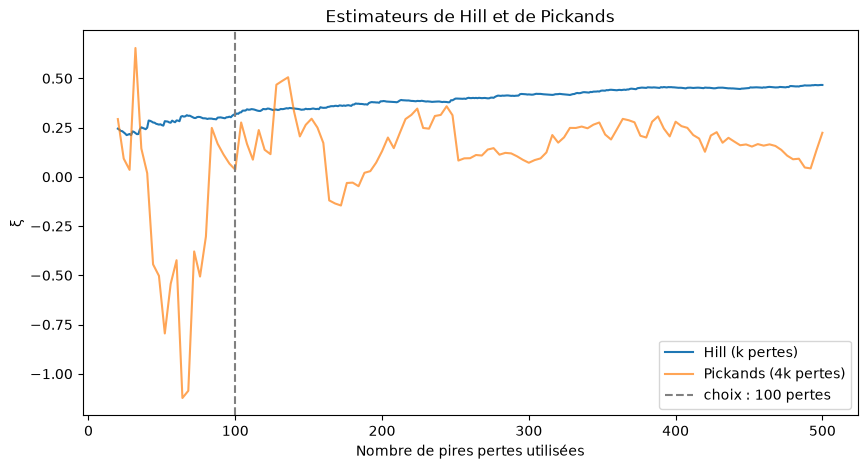

Hill (k=100)    : 0.315
Pickands (k=25) : 0.036


In [8]:
liste_k = range(20, 501)
liste_hill = [hill(losses, k) for k in liste_k]

liste_kp = range(5, 126)
liste_pick = [pickands(losses, k) for k in liste_kp]

plt.figure(figsize=(10, 5))
plt.plot(liste_k, liste_hill, label="Hill (k pertes)")
plt.plot([4 * k for k in liste_kp], liste_pick, label="Pickands (4k pertes)", alpha=0.7)
plt.axvline(100, color="gray", linestyle="--", label="choix : 100 pertes")
plt.xlabel("Nombre de pires pertes utilisées")
plt.ylabel("ξ")
plt.title("Estimateurs de Hill et de Pickands")
plt.legend()
plt.savefig("../figures/hill_pickands.png", dpi=150, bbox_inches="tight")
plt.show()

print("Hill (k=100)    :", round(hill(losses, 100), 3))
print("Pickands (k=25) :", round(pickands(losses, 25), 3))


Pickands (orange) :
- l'estimateur est **très volatil** (de −1,1 à 0,65 pour moins de 100 observations), car il ne repose que sur **trois pertes** (rangs k, 2k et 4k) ;
- aucune zone de stabilité n'apparaît, donc aucun choix de k n'est fiable. Sa valeur pour k = 25 (0,04) n'est pas interprétable seule ;
- au-delà de 200 observations, il reste **positif** (≈ 0,1–0,35).

**Conclusion** : les deux estimateurs indiquent une **queue épaisse (ξ > 0)**, loin de la loi normale (ξ = 0).
Pickands sert de **vérification qualitative** 

In [9]:
k = 100
seuil = pertes_triees.iloc[k]
xi = hill(losses, k)

validation = pd.DataFrame({
    "Observée (%)": [pertes_triees.iloc[r - 1] * 100 for r in [1, 2, 5, 10, 20, 50]],
    "Prédite (%)":  [seuil * (k / r) ** xi * 100 for r in [1, 2, 5, 10, 20, 50]],
}, index=[1, 2, 5, 10, 20, 50])
validation.index.name = "Rang"
validation.round(2)

,Observée (%),Prédite (%)
Rang,,
1,13.10,14.44
2,12.06,11.60
5,8.64,8.69
10,6.45,6.98
20,5.52,5.61
50,4.37,4.20


### Validation de ξ : pertes observées vs pertes prédites

On compare les pires pertes réelles à celles prédites par la règle de Hill,
perte(r) ≈ seuil × (k / r)^ξ, avec k = 100 et ξ ≈ 0,32.

| Rang | Observée | Prédite |
|---|---|---|
| 1 | 13,10 % | 14,44 % |
| 2 | 12,06 % | 11,60 % |
| 5 | 8,64 % | 8,69 % |
| 10 | 6,45 % | 6,98 % |
| 20 | 5,52 % | 5,61 % |
| 50 | 4,37 % | 4,20 % |

Les écarts sont faibles (moins de 10 %) et de signe variable : avec un seul paramètre, la loi de Pareto reproduit
correctement toute la queue, de 4 % à 13 %. Pour la pire perte, la prédiction est légèrement supérieure à l'observation,
ce qui va dans le sens de la prudence. **ξ ≈ 0,32 est donc validé**, et on peut l'utiliser pour extrapoler au-delà
des données (VaR 99,99 %).


## 3. VaR et ES EVT : comparaison avec les autres méthodes

$$\text{VaR}_\alpha = X_{(k+1)} \left(\frac{k}{n(1-\alpha)}\right)^{\xi} \qquad \text{ES}_\alpha = \frac{\text{VaR}_\alpha}{1-\xi} \;\; (\xi < 1)$$

In [10]:
niveaux = [0.99, 0.999, 0.9999]
tableau = pd.DataFrame({
    "Historique":  [var_hist(losses, a) for a in niveaux],
    "Gaussienne":  [var_gaussien(losses, a) for a in niveaux],
    "KDE":         [var_kde(losses, a) for a in niveaux],
    "EVT (Hill)":  [var_evt(losses, a, 100) for a in niveaux],
}, index=["VaR 99 %", "VaR 99,9 %", "VaR 99,99 %"])

tableau.loc["ES 99 %"] = [es_hist(losses, 0.99), es_gaussien(losses, 0.99),
                          es_kde(losses, 0.99), es_evt(losses, 0.99, 100)]
tableau.loc["ES 99,9 %"] = [es_hist(losses, 0.999), es_gaussien(losses, 0.999),
                            es_kde(losses, 0.999), es_evt(losses, 0.999, 100)]

(tableau * 100).round(2)

,Historique,Gaussienne,KDE,EVT (Hill)
VaR 99 %,4.20,3.30,4.23,4.11
"VaR 99,9 %",7.16,4.40,7.41,8.50
"VaR 99,99 %",12.54,5.30,13.09,17.56
ES 99 %,5.76,3.79,5.77,6.00
"ES 99,9 %",10.10,4.80,10.43,12.41


### Interprétation (en % de la valeur du portefeuille)

- **À 99 %**, l'EVT (4,11 %) est proche de l'historique (4,20 %) et de la KDE (4,23 %) : là où les données suffisent,
  les méthodes concordent. La gaussienne (3,30 %) est déjà trop basse.
- **À 99,9 %**, l'EVT donne 8,50 %, contre 7,16 % pour l'historique et 7,41 % pour la KDE.
  Il ne reste qu'environ 5 jours au-delà de ce niveau, et les pires pertes sont très espacées
  (5ᵉ : 8,64 % ; 6ᵉ : 7,36 % ; 7ᵉ : 6,82 %). La VaR historique (7,16 %) n'est pas une perte observée :
  `np.quantile` interpole entre la 6ᵉ et la 7ᵉ pire perte. Une autre convention de calcul la placerait entre
  la 5ᵉ et la 6ᵉ : toute valeur entre ≈ 7,2 % et 8,6 % est donc défendable. Avec si peu d'observations,
  la VaR historique est **imprécise**. L'EVT (8,50 %) se situe dans cette fourchette, et la gaussienne (4,40 %)
  **sous-estime fortement**.
- **À 99,99 %**, l'historique (12,54 %) et la KDE (13,09 %) restent **bloquées sous la pire perte observée** (13,10 %) :
  elles ne peuvent pas extrapoler. L'EVT donne **17,56 %**, une perte jamais observée, estimée grâce à la forme de la queue.
- **ES** : à 99 %, l'ES EVT (6,00 %) est cohérente avec l'historique (5,76 %) ; à 99,9 %, elle est plus élevée (12,41 % contre 10,10 %),
  ce qui reflète l'extrapolation de la queue au-delà des quelques points observés.

*Limite :* plus le niveau est extrême, plus l'estimation dépend de ξ (fourchette 0,30–0,35) : la VaR 99,99 % est un ordre de grandeur,
pas une valeur exacte.

## Conclusion

- La queue des pertes est **épaisse** : ξ ≈ 0,32 (Hill, k = 100), confirmé qualitativement par Pickands.
- La loi de Pareto ajustée **reproduit les pires pertes observées** (écarts < 10 %).
- L'EVT est **cohérente avec l'historique** là où les données existent, et c'est **la seule méthode capable d'extrapoler**
  au-delà de la pire perte observée.
- La loi normale est **inadaptée** aux niveaux extrêmes : 48 dépassements de la VaR 99,9 % au lieu de 5.

**Prochaine étape :** le backtest (partie 5) vérifiera, jour par jour et hors échantillon, quelles méthodes prévoient correctement le risque.